# 04 - Association rule mining with Apriori (from scratch)

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 90)
def show(f, w=900): display(Image(filename=str(ROOT / 'outputs' / 'plots' / f), width=w))

In [2]:
from src.association_rules import run_apriori
summary = run_apriori.run()
summary

2026-11-21 13:03:07,433 | apriori | INFO | PHASE 7 - Apriori started


2026-11-21 13:03:33,641 | apriori | INFO | PHASE 7 complete: {'n_transactions': 11408, 'n_items': 65, 'avg_transaction_length': 5.117198457223002, 'min_support': 0.02, 'min_count': 229, 'min_confidence': 0.6, 'frequent_itemsets': 310, 'by_length': {1: 44, 2: 153, 3: 98, 4: 14, 5: 1}, 'rules': 226, 'rules_lift_gt_1': 225, 'top_rules': 20, 'runtime_s': 0.7466383000137284, 'validation': {'mlxtend_itemsets': 310, 'our_itemsets': 310, 'identical_itemsets': True, 'identical_support_counts': True, 'mlxtend_runtime_s': 1.7027, 'our_runtime_s': 1.1747}, 'figures': ['17_apriori_support_confidence_lift.png', '18_apriori_threshold_sensitivity.png', '19_apriori_levelwise_candidates.png', '20_apriori_top_rules_lift.png']}


{'n_transactions': 11408,
 'n_items': 65,
 'avg_transaction_length': 5.117198457223002,
 'min_support': 0.02,
 'min_count': 229,
 'min_confidence': 0.6,
 'frequent_itemsets': 310,
 'by_length': {1: 44, 2: 153, 3: 98, 4: 14, 5: 1},
 'rules': 226,
 'rules_lift_gt_1': 225,
 'top_rules': 20,
 'runtime_s': 0.7466383000137284,
 'validation': {'mlxtend_itemsets': 310,
  'our_itemsets': 310,
  'identical_itemsets': True,
  'identical_support_counts': True,
  'mlxtend_runtime_s': 1.7027,
  'our_runtime_s': 1.1747},
 'figures': ['17_apriori_support_confidence_lift.png',
  '18_apriori_threshold_sensitivity.png',
  '19_apriori_levelwise_candidates.png',
  '20_apriori_top_rules_lift.png']}

In [3]:
pd.read_csv('outputs/apriori/levelwise_trace.csv')

,k,candidates_joined,pruned,candidates_counted,frequent
0,1,65,0,65,44
1,2,946,0,946,153
2,3,1034,715,319,98
3,4,232,206,26,14
4,5,4,3,1,1
5,6,0,0,0,0


In [4]:
pd.read_csv('outputs/apriori/support_analysis.csv')

,min_support,min_confidence,frequent_itemsets,max_itemset_len,rules,rules_lift_gt_1_2,median_lift,runtime_s
0,0.01,0.5,758,6,1159,1038,4.282282,0.5643
1,0.01,0.6,758,6,781,739,12.239365,0.5643
2,0.01,0.7,758,6,641,636,13.629630,0.5643
3,0.01,0.8,758,6,469,469,12.890395,0.5643
4,0.02,0.5,310,5,299,247,3.130083,0.3925
5,0.02,0.6,310,5,226,206,3.683565,0.3925
6,0.02,0.7,310,5,168,166,4.282282,0.3925
7,0.02,0.8,310,5,122,122,4.267097,0.3925
8,0.03,0.5,165,4,105,78,1.626429,0.3308
9,0.03,0.6,165,4,75,64,3.054980,0.3308


In [5]:
pd.read_csv('outputs/apriori/top_rules.csv')[['antecedent','consequent','support','confidence','lift','leverage','conviction']]

,antecedent,consequent,support,confidence,lift,leverage,conviction
0,"color=bw, format=TV, genre=Suspense/thriller",studio=Shamley (Hitchcock TV),0.024369,1.000000,31.169399,0.023587,inf
1,"color=bw, era=Post-studio (1949-66), genre=Suspense/thriller",studio=Shamley (Hitchcock TV),0.030943,0.863081,26.901706,0.029793,7.069253
2,"era=Post-studio (1949-66), genre=Suspense/thriller",studio=Shamley (Hitchcock TV),0.032083,0.775424,24.169492,0.030755,4.309971
3,era=Silent (<=1927),color=silent_bw,0.053822,0.943164,15.776568,0.050410,16.542744
4,"color=silent_bw, dir_country=USA",era=Silent (<=1927),0.020424,0.882576,15.466089,0.019104,8.030154
5,format=TV,genre=Suspense/thriller,0.024982,0.695122,9.474255,0.022346,3.039348
6,"color=bw, format=TV",era=Post-studio (1949-66),0.024544,0.992908,4.251911,0.018772,108.073633
7,"color=bw, dir_country=USA, genre=Comedy",era=Classical studio (1928-48),0.021739,0.823920,3.678780,0.015830,4.407289
8,"color=bw, later_remade=yes",era=Classical studio (1928-48),0.029891,0.802353,3.582482,0.021548,3.926364
9,"cast 10+, color=bw",era=Classical studio (1928-48),0.021038,0.781759,3.490531,0.015011,3.555859


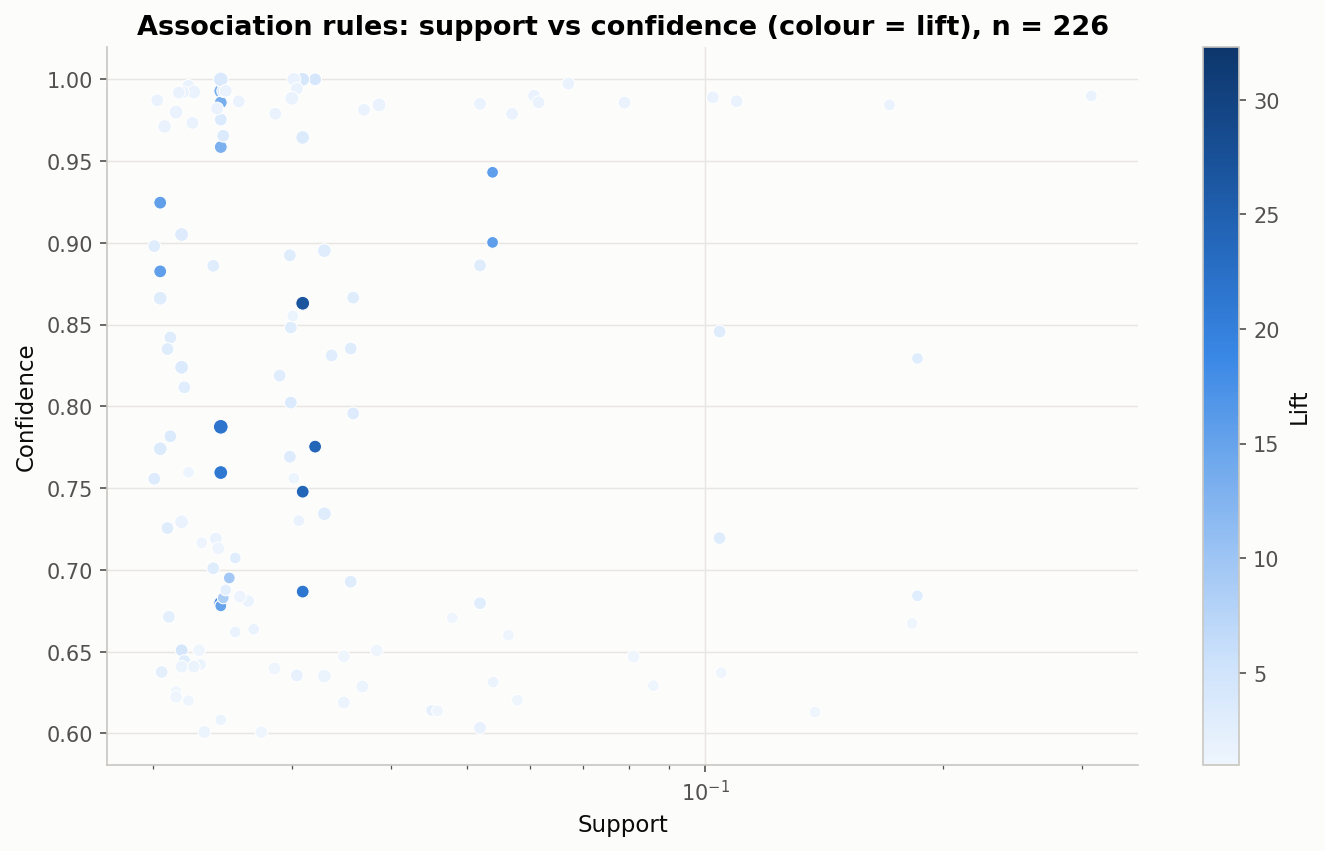

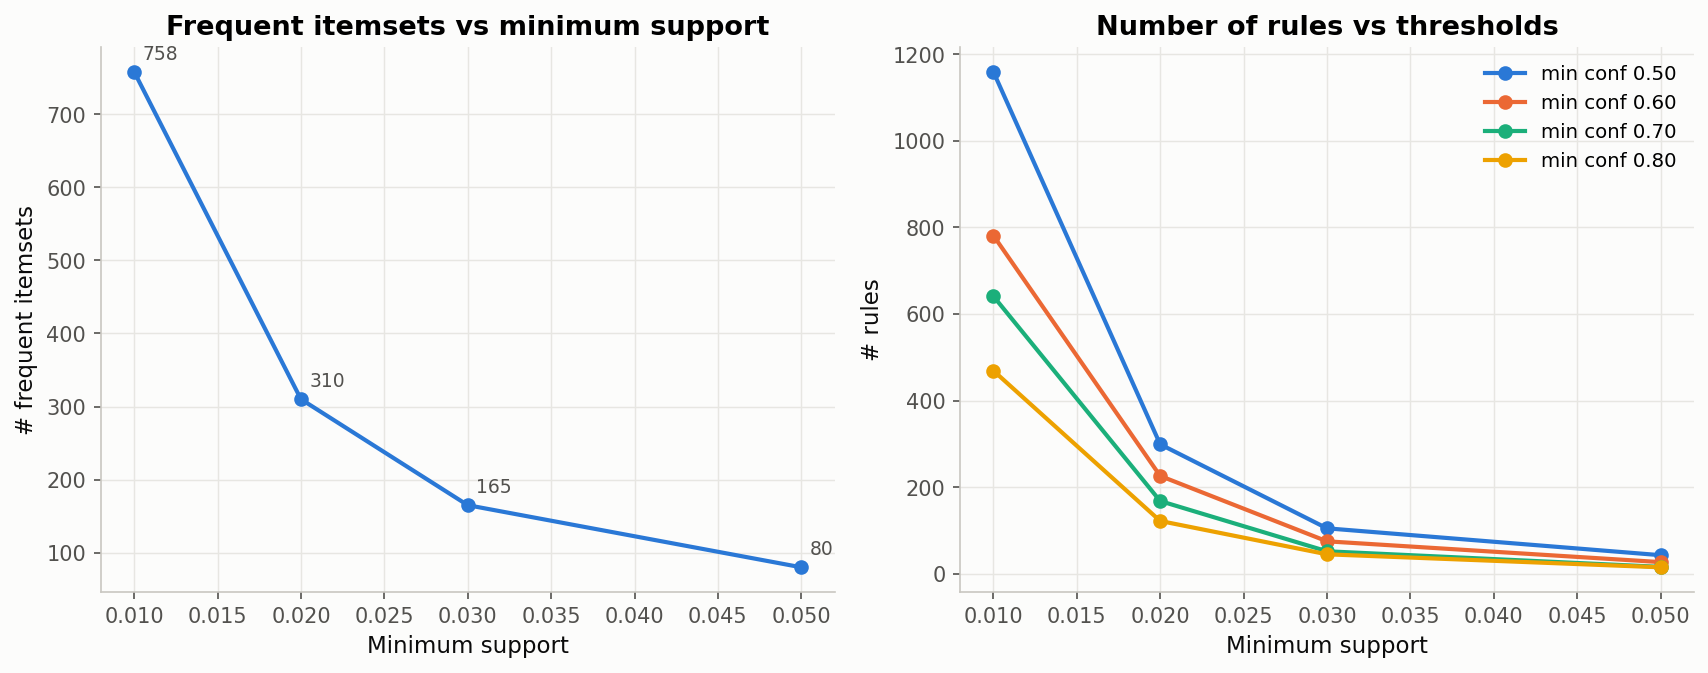

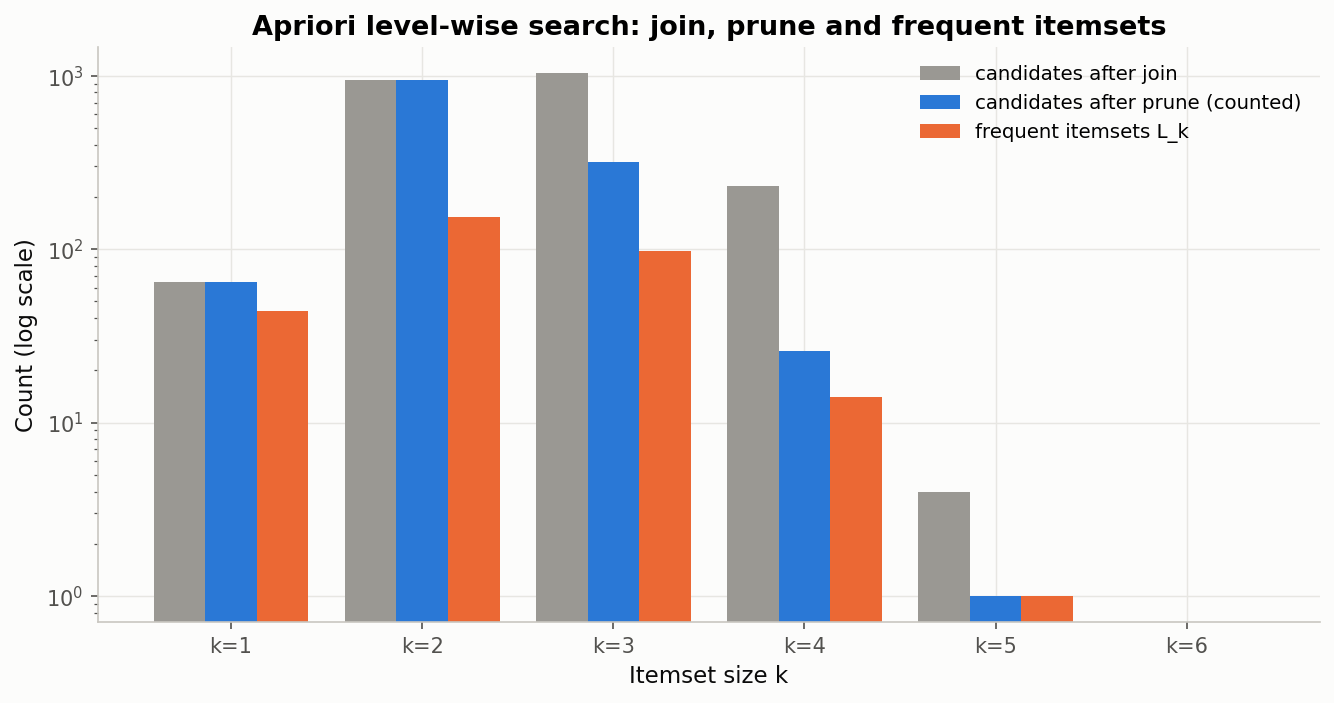

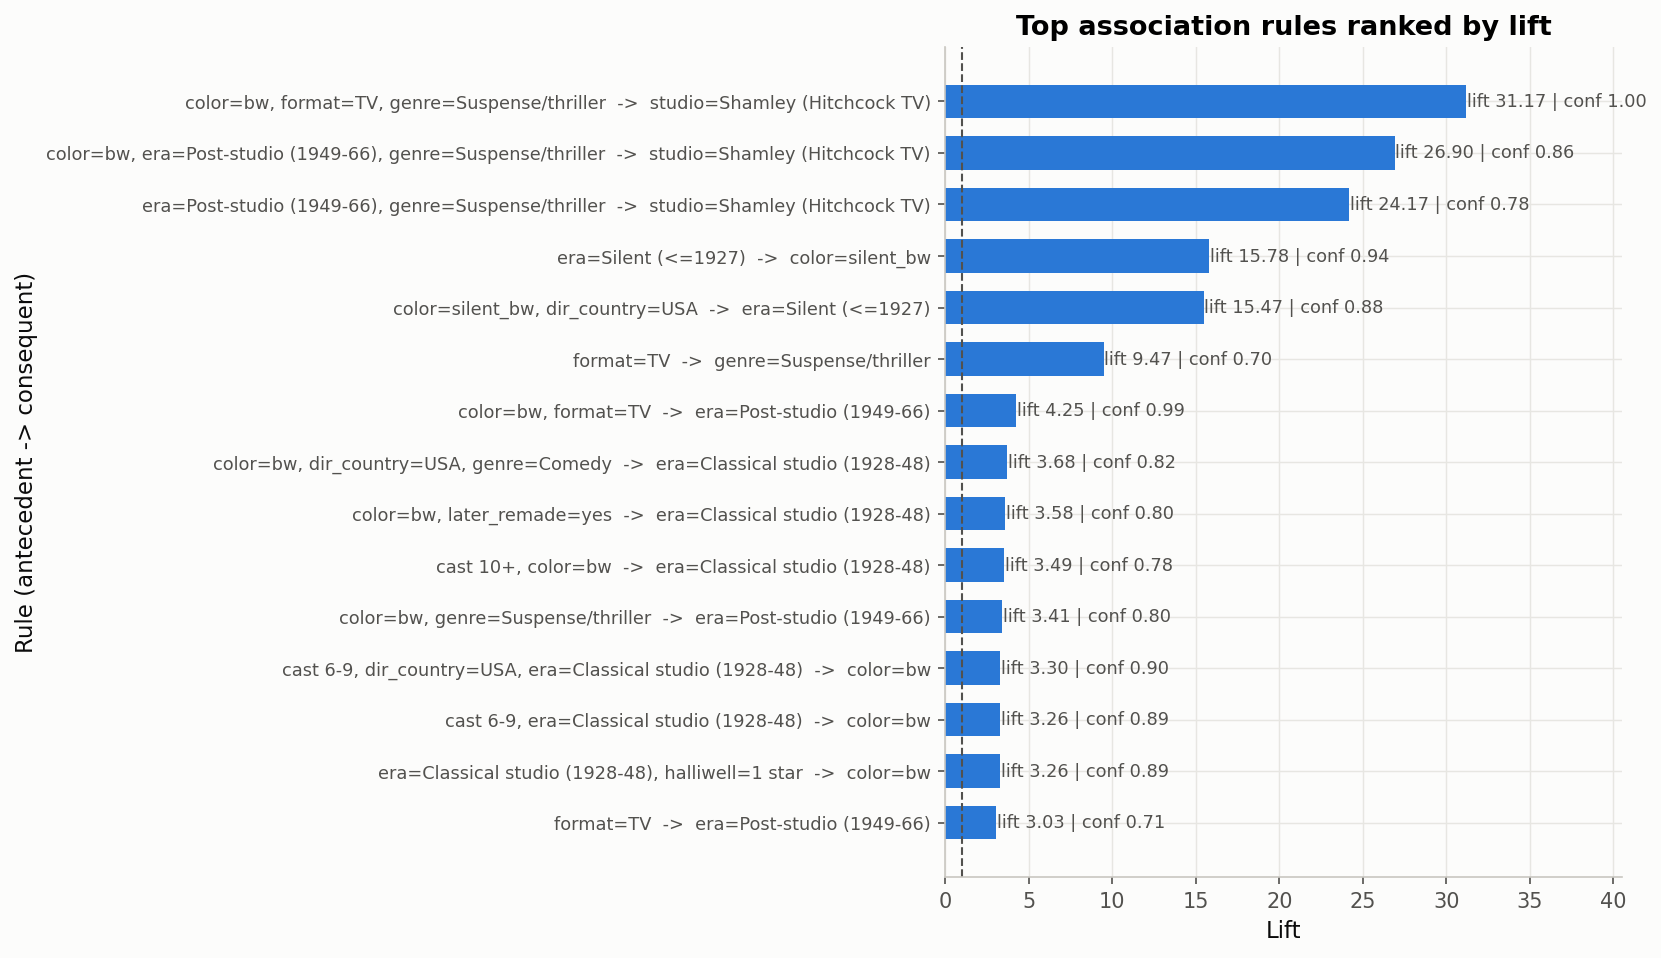

In [6]:
for f in ['17_apriori_support_confidence_lift.png','18_apriori_threshold_sensitivity.png','19_apriori_levelwise_candidates.png','20_apriori_top_rules_lift.png']: show(f)